# Do rises and falls predict volatility differently?

HAR uses today's realized variance as one number. SHAR (Patton & Sheppard,
2015) splits it into the variance from rising and from falling returns, the
semivariances defined in `01_data`, and lets each carry its own weight. This
notebook asks, for every asset, whether the two weights differ, and whether
SHAR forecasts better than HAR because of it.

Methods (walk-forward, smearing, QLIKE, the DM test) are explained in
`02_har`. Every number that depends on the data is printed by the code cell it
comes from.

In [10]:
import _display
import pandas as pd
from _display import COLORS, by_asset, model_table, pair
from design import ASSETS, DESIGN, HAR, HAR_FEATURES, LAYOUT, LOG_RV, LOG_RV_MEANS, MAX_GAP_DAYS

from rvol.data.preparation import TrailingMeanFeatures, build_forecast_data
from rvol.data.volatility import daily_dataset
from rvol.evaluation import diebold_mariano, hac_lag_grid, results_table
from rvol.models import ForecastModel, LinearRegression
from rvol.walkforward import fit_known

_display.use_style()

In [11]:
# Helpers used only by this notebook.
# Short names for the design's choices.
CANDIDATE, LOSS_LABEL = DESIGN.candidate, DESIGN.loss_name
EVALUATION_START, FORECAST_END = DESIGN.evaluation_start, DESIGN.forecast_end


def coefficients(run, model, before):
    # The model's intercept and slopes fitted on every outcome observed before ``before``.
    fitted = fit_known(run.data, model, before=before)
    return pd.Series(
        [fitted.intercept, *fitted.coefficients], index=["intercept", *model.regressors]
    )


def pre_evaluation_fits(run):
    return pd.DataFrame(
        {model.name: coefficients(run, model, EVALUATION_START) for model in MODELS}
    ).loc[["intercept", *HAR_FEATURES, *RISES.columns, *FALLS.columns]]


def quarterly_slopes(run):
    # Refit "at" a date uses every outcome observed up to and including it.
    quarters = pd.date_range(EVALUATION_START, FORECAST_END, freq="QS")
    slopes = {
        quarter.date(): coefficients(run, SHAR, quarter + pd.Timedelta(days=1))[[RISE, FALL]]
        for quarter in quarters
    }
    return pd.DataFrame(slopes).T.set_axis(["b+", "b-"], axis=1).rename_axis("refit at")


def shar_gain(run):
    losses = run.losses()
    return losses[CANDIDATE] - losses["SHAR"]  # positive when SHAR does better


def reverse_tests(run):
    # One-sided DM test that SHAR is better than HAR, at every lag tried.
    losses = run.losses()
    lags = hac_lag_grid(len(losses))
    p_values = [diebold_mariano(losses[CANDIDATE], losses["SHAR"], hac_lags=lag)[1] for lag in lags]
    return pd.Series(p_values, index=pd.Index(lags, name="hac_lags"), name="p-value, SHAR better")


def summary(run):
    table = results_table(run.evaluation)
    har, shar = table.loc[CANDIDATE, LOSS_LABEL], table.loc["SHAR", LOSS_LABEL]
    gain = shar_gain(run)
    months = gain.groupby(gain.index.to_period("M")).mean()
    best = f"{gain.nlargest(10).sum() / gain.sum():.0%}" if gain.sum() > 0 else "no advantage"
    return {
        f"{LOSS_LABEL}, {CANDIDATE}": f"{har:.4f}",
        f"{LOSS_LABEL}, SHAR": f"{shar:.4f}",
        f"SHAR's mean loss below {CANDIDATE}'s by": f"{1 - shar / har:.1%}",
        "sessions SHAR wins": f"{(gain > 0).mean():.0%}",
        "months SHAR wins": f"{(months > 0).sum()} of {len(months)}",
        "advantage from its 10 best sessions": best,
    }


def verdict(run):
    slopes, p = quarterly_slopes(run), reverse_tests(run)
    if (slopes["b+"] > slopes["b-"]).all():
        order = "b+ > b- at every quarterly refit"
    elif (slopes["b-"] > slopes["b+"]).all():
        order = "b- > b+ at every quarterly refit"
    else:
        order = "the slopes' order changes between refits"
    if p.max() < 0.05:
        test = "significant at 5% at every lag"
    elif p.min() < 0.05:
        test = "significant at 5% at some lags only"
    else:
        test = "not significant at 5% at any lag"
    return (
        f"{pair(run.series)}: {order}; SHAR better than {CANDIDATE}: {test} "
        f"(p from {p.min():.3f} to {p.max():.3f})"
    )

## The model

$$
y_{t+1} = a + b^+ \log \mathrm{RS}^+_t + b^- \log \mathrm{RS}^-_t
  + b_w\,\bar y^{(w)}_t + b_m\,\bar y^{(m)}_t
$$

with $y = \log \mathrm{RV}$ and the weekly and monthly means as in HAR. Patton
and Sheppard use levels; logs here match HAR. In stocks, falls usually predict
more volatility than rises ($b^- > b^+$). For a currency pair the sign only says
which currency strengthened, so there is no strong prior either way.

In [12]:
RISES = TrailingMeanFeatures("log_rs_pos", (1,), max_gap_days=MAX_GAP_DAYS)
FALLS = TrailingMeanFeatures("log_rs_neg", (1,), max_gap_days=MAX_GAP_DAYS)
RISE, FALL = RISES.column(1), FALLS.column(1)
SHAR = ForecastModel("SHAR", LinearRegression(), (RISE, FALL, *HAR_FEATURES[1:]))
MODELS = [HAR, SHAR]
display(_display.design_table(DESIGN, ASSETS))
model_table(MODELS)

,study design
assets,EUR/USD
minimum training sessions,252
first forecast target,2024-10-01
evaluation start,2025-01-01
last forecast target,2026-09-30
candidate model,HAR
loss,QLIKE


,rule,settings,regressors
model,,,
HAR,LinearRegression,ridge = 0.0,"log_rv_mean_1, log_rv_mean_5, log_rv_mean_22"
SHAR,LinearRegression,ridge = 0.0,"log_rs_pos_mean_1, log_rs_neg_mean_1, log_rv_m..."


In [13]:
FEATURES = [LOG_RV_MEANS, RISES, FALLS]
DATA = {
    asset: build_forecast_data(daily_dataset(asset, LAYOUT), FEATURES, value_col=LOG_RV)
    for asset in ASSETS
}
RUNS = {asset: DESIGN.run(DATA[asset], MODELS, series=asset) for asset in ASSETS}

## Answer

In [14]:
for run in RUNS.values():
    print(verdict(run))

EUR/USD: b+ > b- at every quarterly refit; SHAR better than HAR: significant at 5% at some lags only (p from 0.021 to 0.059)


Two questions, two kinds of answer. Whether rises and falls carry different
weight is answered by the slopes and their stability across refits. Whether
that makes SHAR the better forecast is a weaker claim: an edge that is
borderline in the DM test and concentrated in a few sessions is suggestive,
not decisive.

## 1. The weights

The coefficients fitted on everything before the evaluation period:

In [15]:
by_asset({asset: pre_evaluation_fits(run) for asset, run in RUNS.items()}).round(3)

,HAR,SHAR
intercept,-1.692,-1.557
log_rv_mean_1,0.125,NaN
log_rv_mean_5,0.468,0.441
log_rv_mean_22,0.255,0.248
log_rs_pos_mean_1,NaN,0.135
log_rs_neg_mean_1,NaN,0.026


One fit can mislead, so here are SHAR's two slopes as the walk-forward refits
them at the start of each quarter of the evaluation period.

In [16]:
by_asset({asset: quarterly_slopes(run) for asset, run in RUNS.items()}).round(3)

,b+,b-
refit at,,
2025-01-01,0.135,0.026
2025-04-01,0.151,0.031
2025-07-01,0.181,0.028
2025-10-01,0.151,0.054
2026-01-01,0.142,0.055
2026-04-01,0.187,0.070
2026-07-01,0.177,0.075


## 2. Does SHAR forecast better?

The study tests every model against HAR, so its usual p-value asks whether HAR
is better than SHAR. Here the question is the reverse: whether SHAR is better
than HAR, with $d_t$ = HAR's loss minus SHAR's, repeated across HAC lags as in
`02_har`. Two descriptive checks go with it: the months in which SHAR does
better, and the share of its advantage that comes from its ten best sessions.

In [17]:
display(
    pd.DataFrame({pair(a): reverse_tests(run) for a, run in RUNS.items()}).T.style.format("{:.3f}")
)
pd.DataFrame({pair(asset): summary(run) for asset, run in RUNS.items()})

hac_lags,0,1,2,3,4,5,10,20,30
EUR/USD,0.021,0.030,0.033,0.034,0.034,0.035,0.042,0.047,0.059


,EUR/USD
"QLIKE, HAR",0.1525
"QLIKE, SHAR",0.1510
SHAR's mean loss below HAR's by,1.0%
sessions SHAR wins,52%
months SHAR wins,10 of 21
advantage from its 10 best sessions,99%


A line that rises steadily is a steady advantage; a line that jumps on a few
days and drifts otherwise is an advantage that rests on those days.

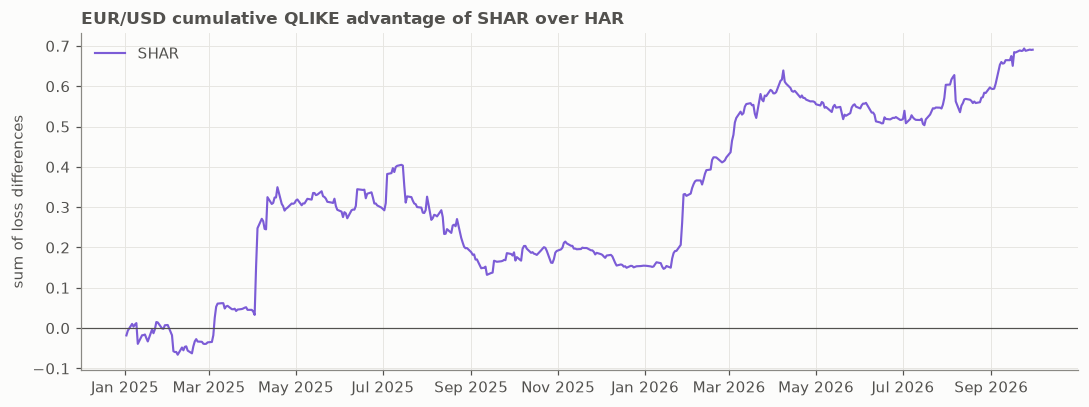

In [18]:
_display.cumulative_advantage(
    {pair(asset): shar_gain(run).cumsum().to_frame("SHAR") for asset, run in RUNS.items()},
    COLORS,
    title=f"cumulative {LOSS_LABEL} advantage of SHAR over {CANDIDATE}",
);

**Caveats.** SHAR was added after HAR was fixed as the candidate, and its test
here is one of several pairwise comparisons, so a p-value near 5% is weak
evidence; `05_best_models` (roadmap Phase 5) asks the question for all models at
once with a model confidence set. In logs, setting $b^+ = b^-$ does not give
HAR back, since $\log \mathrm{RS}^+ + \log \mathrm{RS}^- \ne \log \mathrm{RV}$, so
the slopes' gap is described rather than tested as a restriction.